Training Accuracy: 0.46
Testing Accuracy: 0.43
Precision: 0.43
Recall: 0.43
F1 Score: 0.42

Classification Report:
              precision    recall  f1-score   support

         cel       0.52      0.35      0.42        78
         cla       0.43      0.39      0.41       101
         flu       0.44      0.31      0.36        90
         gac       0.43      0.54      0.48       127
         gel       0.36      0.35      0.36       152
         org       0.45      0.62      0.52       136
         pia       0.49      0.52      0.51       144
         sax       0.32      0.18      0.23       125
         tru       0.49      0.42      0.45       116
         vio       0.39      0.28      0.33       116
         voi       0.40      0.61      0.49       156

    accuracy                           0.43      1341
   macro avg       0.43      0.42      0.41      1341
weighted avg       0.43      0.43      0.42      1341



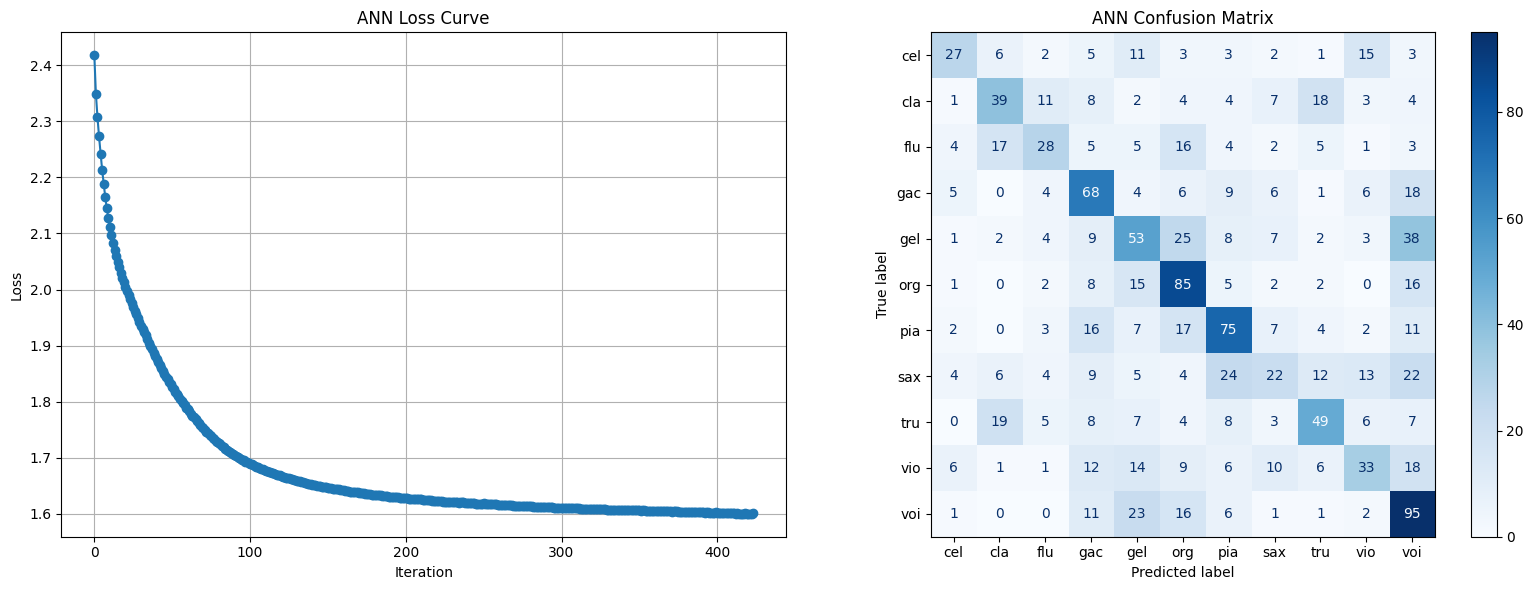

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Load the dataset
music_data = pd.read_csv("C:/Users/LENOVO/Documents/ML Project(Instrument Classifier)/Music Dataset.csv")
X = music_data.drop("Instrument", axis=1)
y = music_data["Instrument"]

# 2. Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Define and train the ANN
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 5),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)

# 5. Evaluation
train_accuracy = accuracy_score(y_train, mlp.predict(X_train_scaled))
test_pred = mlp.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, test_pred)
precision = precision_score(y_test, test_pred, average='weighted')
recall = recall_score(y_test, test_pred, average='weighted')
f1 = f1_score(y_test, test_pred, average='weighted')
conf_mat = confusion_matrix(y_test, test_pred)

print(f"Training Accuracy: {train_accuracy:.2f}")
print(f"Testing Accuracy: {test_accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, test_pred))

# 6. Plot Loss Curve and Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(mlp.loss_curve_, marker='o', linestyle='-')
axes[0].set_title('ANN Loss Curve')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=mlp.classes_).plot(ax=axes[1], cmap='Blues')
axes[1].set_title('ANN Confusion Matrix')

plt.tight_layout()
plt.show()